# **Normalization**
It is a feature scalling technique which scale the numeric feature in a common range such as 0 to 1 or -1 to 1.


# **Min-Max Normalization**

Scale the data in a range of 0 to 1. It is sensitive to outliers.

**Mathematically formula :**

x_scaled = (x - x_min) / (x_max - x_min)


In [62]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [63]:
df = pd.read_csv("data/titanic.csv")


In [64]:
df = pd.read_csv("data/titanic.csv", usecols=["Survived", "Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"])
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df["Age"] = df["Age"].fillna(df["Age"].mean())

X = df.drop(columns=["Survived"])
y = df["Survived"]

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [65]:
from sklearn.preprocessing import MinMaxScaler

scale = MinMaxScaler()
col = ["Pclass", "Age", "SibSp", "Parch", "Fare"]

scale.fit(X_train[col])

,"feature_range feature_range: tuple (min, max), default=(0, 1)Desired range of transformed data.","(0, ...)"
,"copy copy: bool, default=TrueSet to False to perform inplace row normalization and avoid acopy (if the input is already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data toprovided `feature_range`.Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the `feature_range`, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data... versionadded:: 0.24",False


In [66]:
X_train[col] = scale.transform(X_train[col])
X_test[col] = scale.transform(X_test[col])

In [67]:
X_train

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
331,0.0,male,0.566474,0.000,0.000000,0.055628,S
733,0.5,male,0.283740,0.000,0.000000,0.025374,S
382,1.0,male,0.396833,0.000,0.000000,0.015469,S
704,1.0,male,0.321438,0.125,0.000000,0.015330,S
813,1.0,female,0.070118,0.500,0.333333,0.061045,S
...,...,...,...,...,...,...,...
106,1.0,female,0.258608,0.000,0.000000,0.014932,S
270,0.0,male,0.367921,0.000,0.000000,0.060508,S
860,1.0,male,0.509927,0.250,0.000000,0.027538,S
435,0.0,female,0.170646,0.125,0.333333,0.234224,S


In [68]:

def check(col_name):
    print("\nBefore Scalling the", col_name)
    print("min :", int(df[col_name].min()))
    print("max :", int(df[col_name].max()))
    print("\nAfter Scalling the", col_name)
    print("min :", int(X_train[col_name].min()))
    print("max :", int(X_train[col_name].max()))
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    sns.kdeplot(data=df, x=col_name, ax=axes[0])
    axes[0].set_title("Distribution before scalling")
    
    sns.kdeplot(data=X_train, x=col_name, ax=axes[1])
    axes[1].set_title("Distribution after scalling")
    fig.show()

In [69]:
import warnings

warnings.filterwarnings("ignore")


Before Scalling the Age
min : 0
max : 80

After Scalling the Age
min : 0
max : 1


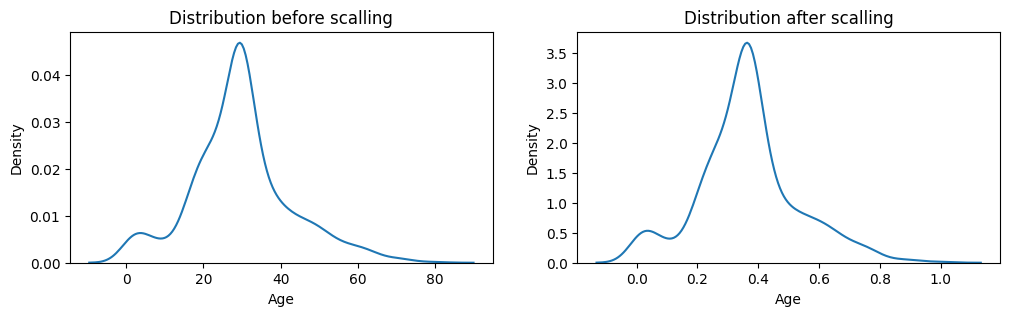

In [70]:
check("Age")


Before Scalling the Fare
min : 0
max : 512

After Scalling the Fare
min : 0
max : 1


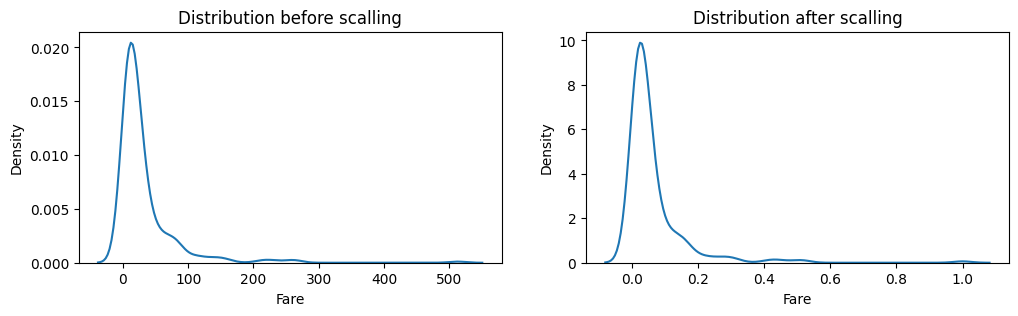

In [71]:
check("Fare")

# **Mean Normalization**

It moves the center of the data to zero, then scales the values according to the difference between the maximum and minimum.
Sklearn don't have dedicated class for mean normalization so we have to implement this by ourself.


**Mathematically formula :**

x_norm = (x - mean) / (max - min)


In [72]:
def mean_normalizer(ser:pd.Series):
    nomi = ser-ser.mean()
    denomi = ser.max()-ser.min()
    return nomi/denomi


In [73]:
df["Age_mean_normalizer"] = mean_normalizer(df["Age"])

<Axes: xlabel='Age', ylabel='Density'>

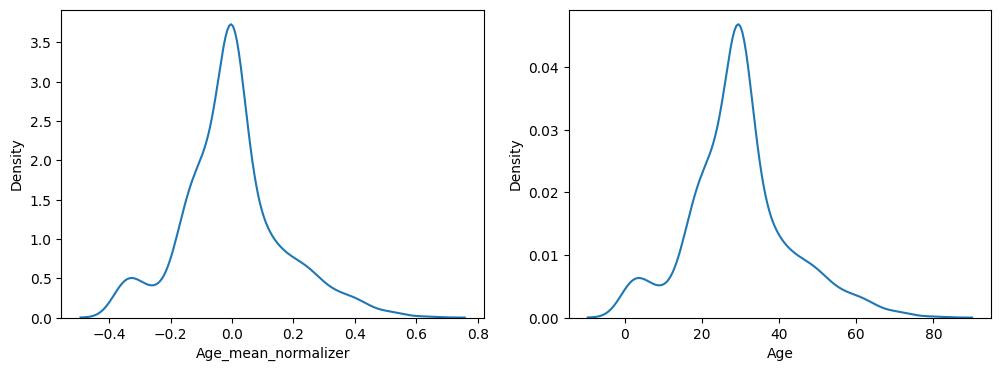

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(df["Age_mean_normalizer"], ax=ax[0])
sns.kdeplot(df["Age"], ax=ax[1])

<br>

# **Max Absolute Normalizer**

Use this when your data have large number of zeros as it preserve zeros.

**Mathematically formule :**

X_scaled = X / max(abs(X))

In [75]:
from sklearn.preprocessing import MaxAbsScaler

scale = MaxAbsScaler()

scale.fit(X_train[col])

,"copy copy: bool, default=TrueSet to False to perform inplace scaling and avoid a copy (if the inputis already a numpy array).",True
,"clip clip: bool, default=FalseSet to True to clip transformed values of held-out data to [-1, 1].Since this parameter will clip values, `inverse_transform` may notbe able to restore the original data... note:: Setting `clip=True` does not prevent feature drift (a distribution shift between training and test data). The transformed values are clipped to the [-1, 1] range, which helps avoid unintended behavior in models sensitive to out-of-range inputs (e.g. linear models). Use with care, as clipping can distort the distribution of test data.",False


In [76]:
X_train[col] = scale.transform(X_train[col])
X_test[col] = scale.transform(X_test[col])


In [77]:
X_train["Age"].min()

0.0

<Axes: xlabel='Age', ylabel='Density'>

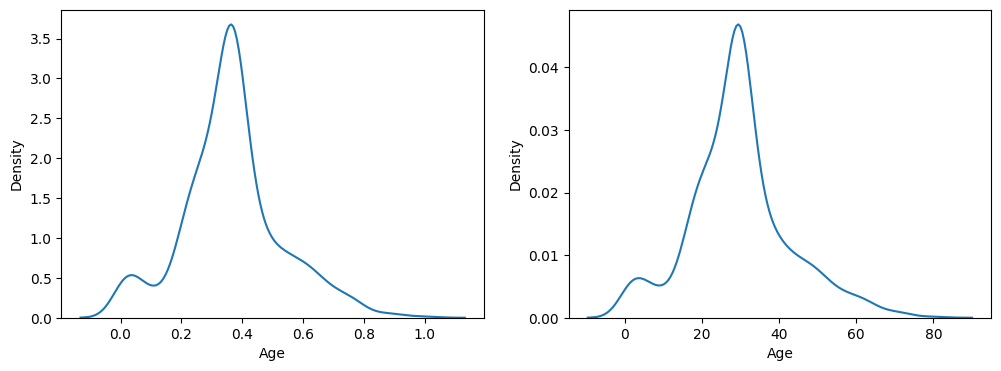

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(X_train["Age"], ax=ax[0])
sns.kdeplot(df["Age"], ax=ax[1])

# **Robust Normalizer**

It is specially design to reduce the influency of outliers.

**Mathematically formule :**

X_scaled = (X - Median) / (Q3 - Q1)


In [79]:
from sklearn.preprocessing import RobustScaler

scale = RobustScaler()

scale.fit(X_train[col])

,"with_centering with_centering: bool, default=TrueIf `True`, center the data before scaling.This will cause :meth:`transform` to raise an exception when attemptedon sparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_scaling with_scaling: bool, default=TrueIf `True`, scale the data to interquartile range.",True
,"quantile_range quantile_range: tuple (q_min, q_max), 0.0 < q_min < q_max < 100.0, default=(25.0, 75.0)Quantile range used to calculate `scale_`. By default this is equal tothe IQR, i.e., `q_min` is the first quantile and `q_max` is the thirdquantile... versionadded:: 0.18","(25.0, ...)"
,"copy copy: bool, default=TrueIf `False`, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"unit_variance unit_variance: bool, default=FalseIf `True`, scale data so that normally distributed features have avariance of 1. In general, if the difference between the x-values of`q_max` and `q_min` for a standard normal distribution is greaterthan 1, the dataset will be scaled down. If less than 1, the datasetwill be scaled up... versionadded:: 0.24",False


In [80]:
X_train[col] = scale.transform(X_train[col])
X_test[col] = scale.transform(X_test[col])

<Axes: xlabel='Fare', ylabel='Density'>

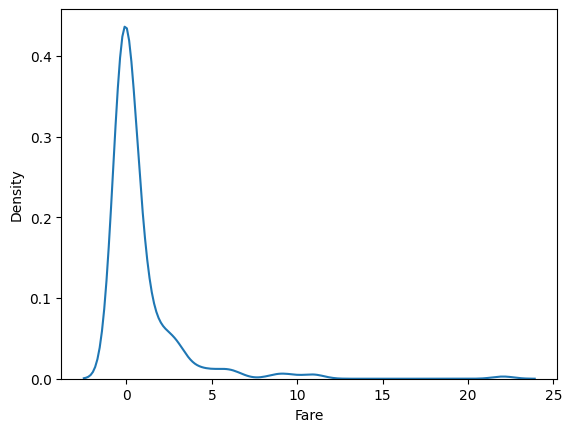

In [81]:
sns.kdeplot(X_train["Fare"])

<br>

# **When to use which one:**

- Want 0 to 1? → Min-Max Scaling.

- Want mean-centered values divided by range? → Mean Normalization.

- Want to preserve zeros in sparse data? → MaxAbs Scaling.

- Have outliers? → Robust Scaling.

- Want mean 0 and standard deviation 1? → Standardization.